# Train your first surrogate

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


Train a surrogate, check its predictions, then save it for reuse. This tutorial
runs on a CPU using the bundled SIRDS epidemic simulations. If you are running
locally, follow [installation](https://ojwatson.github.io/metis/basics/installing_metis.html) first.

## Look at the simulations

The bank contains 100 parameter settings, each simulated five times on the same
40-point time grid. The inputs describe transmission and recovery; the outputs
are susceptible, infected, recovered and dead population counts.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from pathlib import Path

from metis import load_example, Surrogate, TrainingConfig

torch.set_num_threads(2)
bank = load_example()
print(f"{len(bank)} runs × {len(bank.times)} timepoints")
print("Inputs:", ", ".join(bank.input_names))
print("Outputs:", ", ".join(bank.output_names))

500 runs × 40 timepoints
Inputs: I_0, beta, gamma, omega, mu
Outputs: S_t, I_t, R_t, D_t


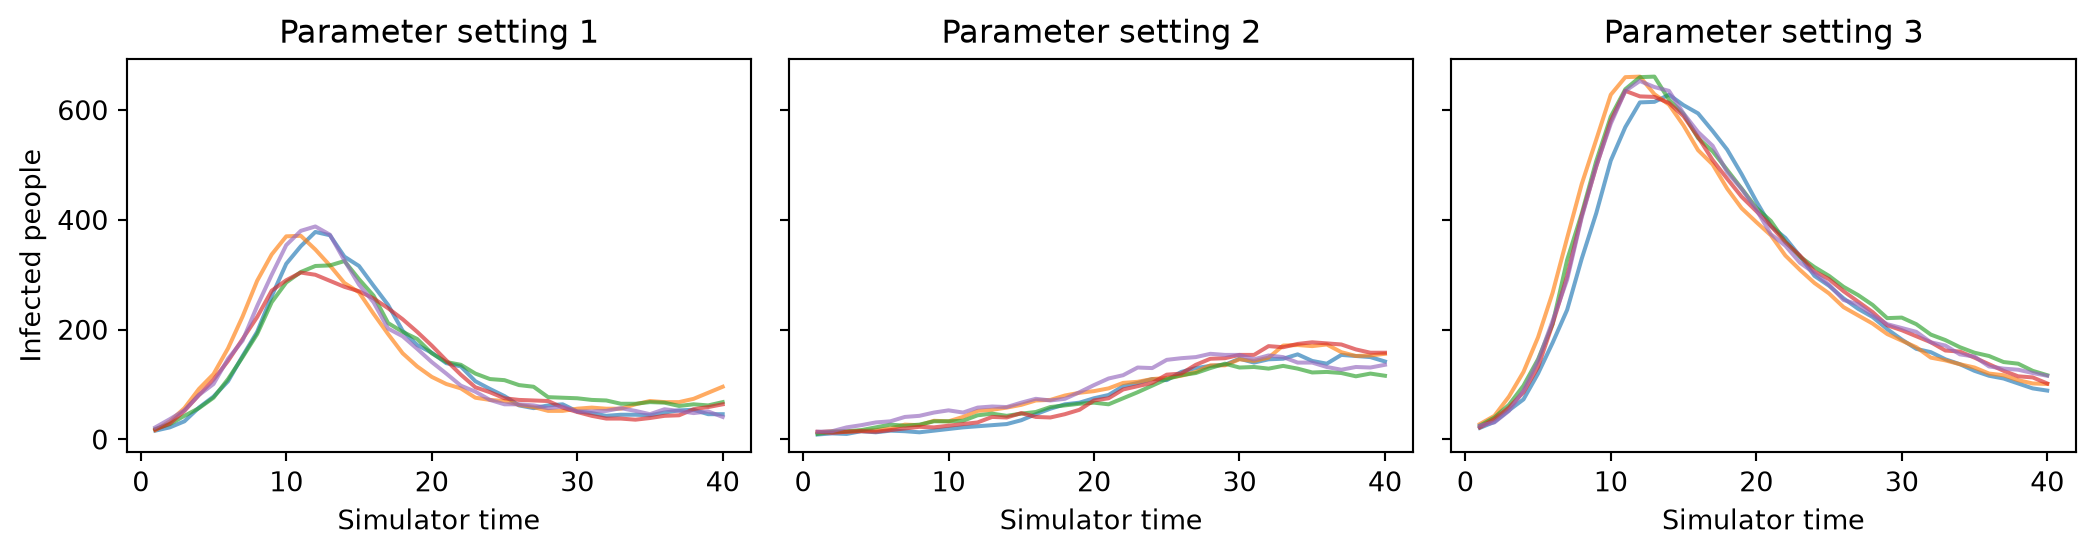

In [2]:
#| code-fold: true
#| code-summary: Show plotting code
#| label: fig-quickstart-bank
#| fig-cap: 'Bundled SIRDS bank: infected counts for three parameter settings, with all five simulator replicates shown.'
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
infected = bank.output_names.index("I_t")
groups = list(dict.fromkeys(bank.group_keys))[:3]
for ax, group in zip(axes, groups):
    indices = [i for i, key in enumerate(bank.group_keys) if key == group]
    for i in indices:
        ax.plot(bank.times, bank.outputs[i, :, infected], alpha=0.65)
    ax.set(xlabel="Simulator time", title=f"Parameter setting {groups.index(group) + 1}")
axes[0].set_ylabel("Infected people")
fig.tight_layout()
plt.show()

*Bundled SIRDS bank: infected counts for three parameter settings, with all five simulator replicates shown.*

## Fit an MLP

Keep all replicates of a parameter setting together when splitting the bank.
Training learns the model, validation chooses the best checkpoint, and the test
set measures performance on settings that neither step has used.

In [3]:
split = bank.split(validation_fraction=0.2, test_fraction=0.2, seed=42)
print({name: len(getattr(split, name)) for name in ("train", "validation", "test")})

model = Surrogate("mlp").fit(
    split.train,
    validation=split.validation,
    config=TrainingConfig(steps=500, eval_every=50, seed=42, device="cpu"),
)

{'train': 300, 'validation': 100, 'test': 100}


A *step* is one optimizer update. This MLP predicts one trajectory per input
setting; it does not generate the variation between simulator replicates.

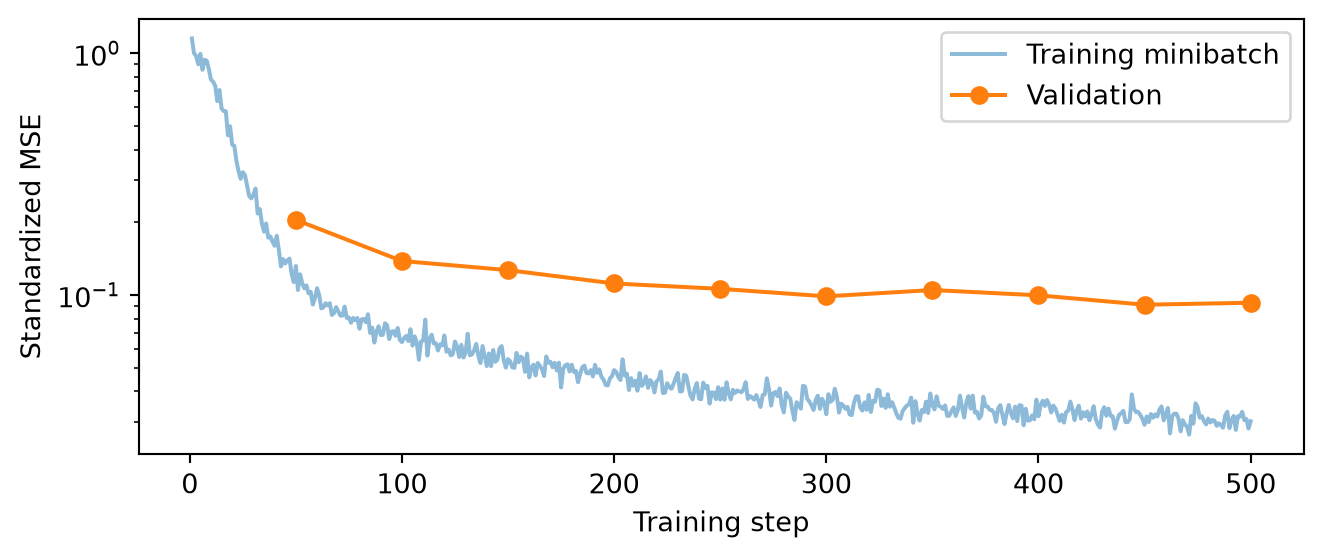

In [4]:
#| code-fold: true
#| code-summary: Show plotting code
#| label: fig-quickstart-loss
#| fig-cap: 'MLP fitted to the SIRDS training partition: standardized mean squared error during 500 optimizer updates.'
history = pd.DataFrame(model.history)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history["step"], history["train_loss"], alpha=0.5, label="Training minibatch")
validation = history.dropna(subset=["validation_loss"])
ax.plot(validation["step"], validation["validation_loss"], "o-", label="Validation")
ax.set(xlabel="Training step", ylabel="Standardized MSE", yscale="log")
ax.legend()
fig.tight_layout()
plt.show()

*MLP fitted to the SIRDS training partition: standardized mean squared error during 500 optimizer updates.*

## Check predictions on held-out simulations

RMSE and MAE are errors in the original population-count units. Inspect each
output separately: an acceptable error depends on how you plan to use it.

In [5]:
report = model.evaluate(split.test)
report.by_output.to_pandas().round(2)

/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma', 'omega', 'mu']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


,output,rmse,mae
0,S_t,55.25,40.39
1,I_t,32.08,23.47
2,R_t,42.00,30.40
3,D_t,14.21,10.33


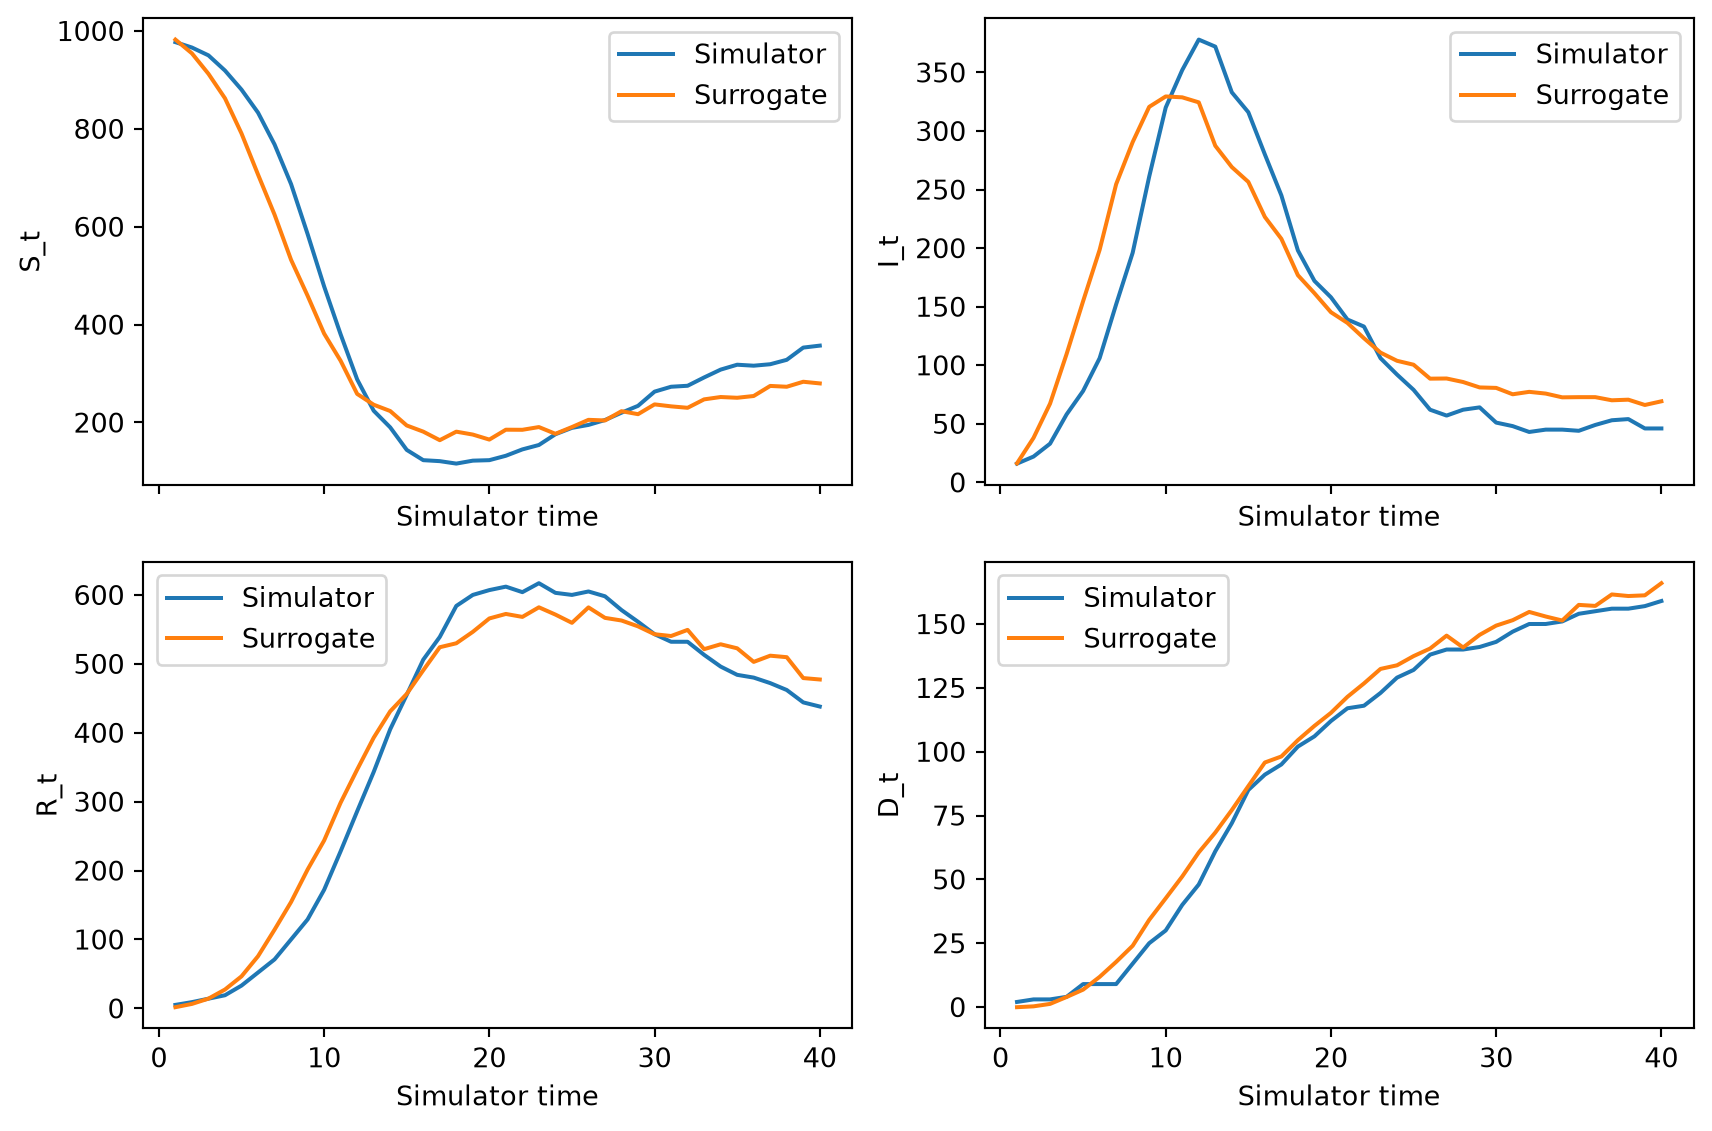

In [6]:
#| code-fold: true
#| code-summary: Show plotting code
#| label: fig-quickstart-test
#| fig-cap: 'MLP fitted to the SIRDS training partition: generated trajectories against the first held-out test realization.'
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
for c, ax in enumerate(axes.flat):
    ax.plot(bank.times, report.observed[0, :, c], label="Simulator")
    ax.plot(bank.times, report.predictions[0, :, c], label="Surrogate")
    ax.set(xlabel="Simulator time", ylabel=bank.output_names[c])
    ax.legend()
fig.tight_layout()
plt.show()

*MLP fitted to the SIRDS training partition: generated trajectories against the first held-out test realization.*

A successful fit is the start of evaluation. Continue with
[model comparison](https://ojwatson.github.io/metis/package/model-choice.html) and [fidelity checks](https://ojwatson.github.io/metis/package/evaluation.html)
before relying on a surrogate for research.

## Save, reload and predict

The saved model includes input/output names, the time grid and fitted scaling.
Prediction needs only the artifact and new inputs, not the simulation bank.

In [7]:
output = Path("quickstart-output")
output.mkdir(exist_ok=True)
model.save(output / "surrogate.pt")
report.save(output / "evaluation.json")

restored = Surrogate.load(output / "surrogate.pt")
query = dict(zip(bank.input_names, split.test.inputs[0].tolist()))
prediction = restored.predict(query)
print("New input settings:", query)
print("Prediction shape (settings, timepoints, outputs):", prediction.shape)
np.testing.assert_allclose(prediction, model.predict(query))
pd.DataFrame(prediction[0], columns=restored.output_names, index=restored.times).head()

New input settings: {'I_0': 0.012044086121022701, 'beta': 0.7847431302070618, 'gamma': 0.21870319545269012, 'omega': 0.039242882281541824, 'mu': 0.029306387528777122}
Prediction shape (settings, timepoints, outputs): (1, 40, 4)


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


,S_t,I_t,R_t,D_t
1.0,982.214111,16.243269,1.651816,-0.051962
2.0,954.056091,37.966480,6.407017,0.280576
3.0,912.264526,67.193573,14.068363,1.239972
4.0,862.274353,109.522385,27.294807,3.939400
5.0,790.442017,154.677750,46.431271,6.822608


Replace `query` with your own named input values. METIS warns if you move outside
the fitted input ranges. Next, [bring your own simulation bank](https://ojwatson.github.io/metis/package/own-bank.html).

Prefer a configuration-driven run? [Hydra](https://ojwatson.github.io/metis/package/hydra.html) uses the same training API:

```bash
uv run metis train model=mlp training.steps=500
```